In [2]:
import numpy as np
from matplotlib import pyplot as plt

In [3]:
def asarray_1d_float(x):
    part_1 = "x could not be converted to a "
    part_2 = "0D or 1D "
    part_3 = "numpy array of floats"
    try:
        X = np.asarray(x, dtype=float)
    except (TypeError, ValueError) as e:
        error_message = part_1 + part_3
        raise ValueError(error_message)
    if (X.ndim != 0) and (X.ndim != 1):    
        error_message = part_1 + part_2 + part_3
        raise ValueError(error_message)
    return X

In [4]:
def di2xyz(dec, inc):
    # Convert input to 1D numpy arrays of floats
    D = asarray_1d_float(dec)
    I = asarray_1d_float(inc)
    # Convert degrees to radians
    D = np.deg2rad(D)
    I = np.deg2rad(I)
    # Compute the Cartesian coordinates
    x = np.cos(I) * np.cos(D)
    y = np.cos(I) * np.sin(D)
    z = np.sin(I)
    return x, y, z

In [5]:
def di2equal_area_polar(dec, inc):
    # Compute the Cartesian coordinates
    x, y, z = di2xyz(dec, inc)
    # Compute the equal area radius
    r_xy = np.sqrt(1 - np.abs(z))
    h_xy = np.sqrt(x**2 + y**2)
    # Zero h
    zero_h = (np.abs(h_xy) <= 1e-10)
    # Compute the projected coordinates
    x_eqarea = np.empty_like(x)
    y_eqarea = np.empty_like(x)
    x_eqarea[zero_h] = 0.
    y_eqarea[zero_h] = 0.
    x_eqarea[~zero_h] = ( r_xy[~zero_h] / h_xy[~zero_h] ) * x[~zero_h]
    y_eqarea[~zero_h] = ( r_xy[~zero_h] / h_xy[~zero_h] ) * y[~zero_h]
    return x_eqarea, y_eqarea

In [6]:
def di2equal_area_equatorial(dec, inc):
    # Compute the Cartesian coordinates
    x, y, z = di2xyz(dec, inc)
    # Compute the equal area radius
    r_yz = np.sqrt(1 - np.abs(x))
    h_yz = np.sqrt(y**2 + z**2)
    # Zero h
    zero_h = (np.abs(h_yz) <= 1e-10)
    # Compute the projected coordinates
    y_eqarea = np.empty_like(x)
    z_eqarea = np.empty_like(x)
    y_eqarea[zero_h] = 0.
    z_eqarea[zero_h] = 0.
    y_eqarea[~zero_h] = ( r_yz[~zero_h] / h_yz[~zero_h] ) * y[~zero_h]
    z_eqarea[~zero_h] = ( r_yz[~zero_h] / h_yz[~zero_h] ) * z[~zero_h]
    return y_eqarea, z_eqarea

In [6]:
dec = np.linspace(-180., 180., 30)
inc = np.broadcast_to(-50., (dec.size,))

In [7]:
def plot_polar_net(ax):
    
    # Declination and inclination values
    decs = np.arange(0, 361)
    incs = np.arange(0, 91)
    
    # Constant declination lines
    for inc in range(0, 80, 10):
        x, y = di2equal_area_polar(
            decs, np.broadcast_to(inc, (decs.size,))
        )
        ax.plot(y, x, linestyle='-', linewidth=0.3, color=3*(0.3,))
    # Constant inclination lines
    for dec in range(0, 361-10, 10):
        x, y = di2equal_area_polar(
            np.broadcast_to(dec, (incs.size,)), incs
        )
        ax.plot(y, x, linestyle='-', linewidth=0.3, color=3*(0.3,))

In [18]:
def plot_equatorial_net(ax):
    
    # Declination and inclination values
    decs = np.arange(0, 361)
    incs = np.arange(-90, 91)
    
    # Constant declination lines
    for inc in range(-80, 80, 10):
        y, z = di2equal_area_equatorial(
            decs, np.broadcast_to(inc, (decs.size,))
        )
        ax.plot(y, z, linestyle='-', linewidth=0.3, color=3*(0.3,))
    # Constant inclination lines
    for dec in range(0, 361-10, 10):
        y, z = di2equal_area_equatorial(
            np.broadcast_to(dec, (incs.size,)), incs
        )
        ax.plot(y, z, linestyle='-', linewidth=0.3, color=3*(0.3,))

In [19]:
dec, inc = 45, 0

In [20]:
xp, yp = di2equal_area_polar(dec, inc)

In [21]:
ye, ze = di2equal_area_equatorial(dec, inc)

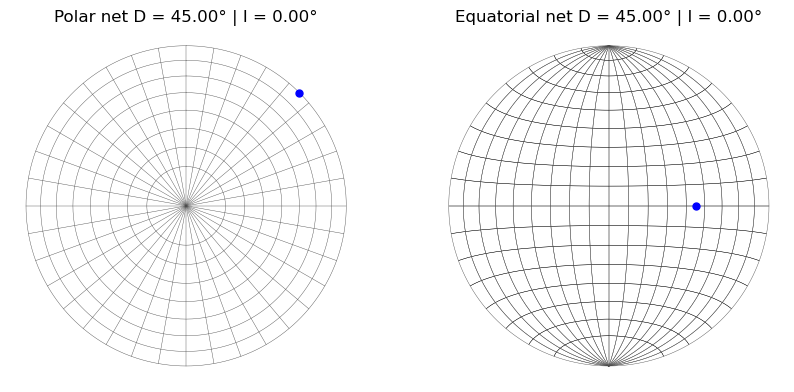

In [24]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, figsize=(10,10)
)

ax = axs[0]
ax.axis('scaled')
ax.set_title(f"Polar net D = {dec:.2f}° | I = {inc:.2f}°")
plot_polar_net(ax)
ax.plot(yp, xp, 'bo', ms=5)
ax.axis("off")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)

ax = axs[1]
ax.axis('scaled')
ax.set_title(f"Equatorial net D = {dec:.2f}° | I = {inc:.2f}°")
plot_equatorial_net(ax)
ax.plot(ye, ze, 'bo', ms=5)
ax.axis("off")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim( 1.1,-1.1)

plt.show()